# A university wants to investigate whether gender is associated with students' preferred learning methods.

# The university surveys 300 students and collects the following data:

In [64]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency


In [65]:
Gender = np.array(["male","female"])
online = np.array([60,35])
class_room = np.array([30,55])
hybrid = np.array([40,80])
df = pd.DataFrame({"Gender":Gender,"Online":online,"Classroom":class_room,"hybrid":hybrid})
df


,Gender,Online,Classroom,hybrid
0,male,60,30,40
1,female,35,55,80


In [66]:
observed_frequency = df[["Online","Classroom","hybrid"]]
total_students = observed_frequency.sum().sum()
rows_total = observed_frequency.sum(axis=1)
columns_total = observed_frequency.sum(axis=0)
print("total students : ",total_students)
print("gender wise total students : ",rows_total)
print("__"*34)
print("total students by learning method : \n",columns_total)

total students :  300
gender wise total students :  0    130
1    170
dtype: int64
____________________________________________________________________
total students by learning method : 
 Online        95
Classroom     85
hybrid       120
dtype: int64


In [67]:
degree_of_freedom = 4 - 1 
print("degree of freedom : ",degree_of_freedom)

degree of freedom :  3


In [68]:
expected_freq = np.outer(rows_total,columns_total/total_students)
expected_df = pd.DataFrame(expected_freq,index = Gender,columns=observed_frequency.columns)
expected_df

,Online,Classroom,hybrid
male,41.166667,36.833333,52.0
female,53.833333,48.166667,68.0


In [69]:
alpha = 0.05
chi_square_Stats,dof,p_value,expected_scipy = chi2_contingency(observed_frequency)
print("chi square stats : ",chi_square_Stats)
print("dof : ",dof)
print("p value : ",p_value)
print("expected scipy :\n",expected_scipy)


chi square stats :  22.328845803622716
dof :  1.4169441747718086e-05
p value :  2
expected scipy :
 [[41.16666667 36.83333333 52.        ]
 [53.83333333 48.16666667 68.        ]]


In [70]:
if p_value < alpha:
    print("\nDecision: Reject the null hypothesis.")
    print("Conclusion: There is sufficient statistical evidence")
    print("that gender and preferred learning method are associated.")

else:
    print("\nDecision: Fail to reject the null hypothesis.")
    print("Conclusion: There is insufficient statistical evidence")
    print("that gender and preferred learning method are associated.")


Decision: Fail to reject the null hypothesis.
Conclusion: There is insufficient statistical evidence
that gender and preferred learning method are associated.


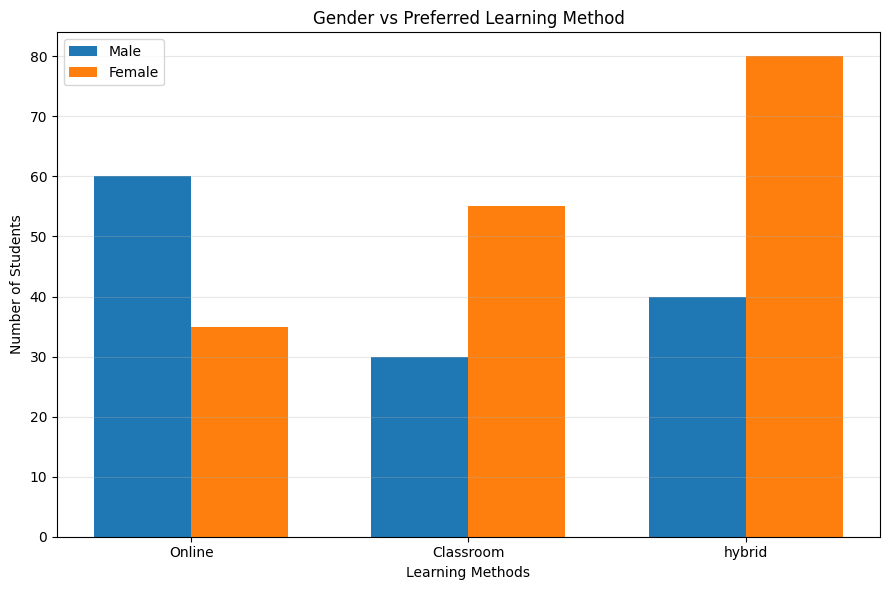

In [73]:
x = np.arange(len(observed_frequency.columns))
width = 0.35
plt.figure(figsize=(9, 6))
# Male bars
plt.bar(
    x - width/2,
    observed_frequency.iloc[0],
    width,
    label="Male"
)
# Female bars
plt.bar(
    x + width/2,
    observed_frequency.iloc[1],
    width,
    label="Female"
)
plt.xlabel("Learning Methods")
plt.ylabel("Number of Students")
plt.title("Gender vs Preferred Learning Method")
plt.xticks(x, observed_frequency.columns)
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()
